# Cryogenic phase equilibrium with NeqSim
Version 1.0.0 · Released NeqSim 3.29.0 teaching example.

Companion to [NeqSim #5281](https://github.com/equinor/neqsim/issues/5281) and [Nwosi (2025)](https://doi.org/10.53022/oarjet.2025.8.2.0038). Reproduce the paper's normal-boiling comparison for pure methane and hydrogen, then extend it to a dry, synthetic LNG feed. Run top to bottom in a fresh Colab session.

| Model | Role in this notebook |
|---|---|
| SRK, PR, PR78 | Industrial cubic EOS comparison. PR78 can overlap PR for these light components. |
| SRK-CPA | Association-capable EOS. This dry feed does not exercise water association. |
| UMR-PRU | PR with a UNIFAC-based mixing rule for the mixture. |
| GERG-2008 | Multiparameter mixture EOS. A successful flash alone does not establish validity. |
| Leachman | Pure normal hydrogen, with no spin conversion kinetics. |
| CoolProp HEOS | Independently implemented pure-fluid EOS reference. Its agreement with Leachman checks the implementation and units, since both use the underlying Leachman formulation. |

In [1]:
%pip -q install neqsim==3.29.0 CoolProp==8.1.0


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from importlib.metadata import version
from io import BytesIO

from base64 import b64encode
from IPython.display import display
import sys

from CoolProp.CoolProp import PropsSI
import jpype
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from neqsim import jneqsim

for package in ("neqsim", "CoolProp", "jpype1", "numpy", "pandas", "matplotlib"):
    print(f"{package}: {version(package)}")
print(f"Python: {sys.version.split()[0]}")
print(f"Java: {jpype.JClass('java.lang.System').getProperty('java.version')}")

systems = jneqsim.thermo.system
Operations = jneqsim.thermodynamicoperations.ThermodynamicOperations
model_classes = {
    "SRK": systems.SystemSrkEos,
    "PR": systems.SystemPrEos,
    "PR78": systems.SystemPrEos1978,
    "SRK-CPA": systems.SystemSrkCPAstatoil,
    "UMR-PRU": systems.SystemUMRPRUMCEos,
    "GERG-2008": systems.SystemGERG2008Eos,
    "Leachman": systems.SystemLeachmanEos,
}
mixture_models = list(model_classes)[:-1]

def make_fluid(model, composition, temperature_k, pressure_bara):
    assert np.isclose(sum(composition.values()), 1.0)
    fluid = model_classes[model](float(temperature_k), float(pressure_bara))
    for component, fraction in composition.items():
        fluid.addComponent(component, float(fraction))
    if len(composition) > 1 and model != "GERG-2008":
        if model == "UMR-PRU":
            fluid.setMixingRule("HV", "UNIFAC_UMRPRU")
        else:
            fluid.setMixingRule("classic")
    return fluid

def active_phases(fluid):
    return [fluid.getPhase(index) for index in range(fluid.getNumberOfPhases())]

def initialize(fluid):
    fluid.init(3)
    fluid.initPhysicalProperties()
    return fluid

def tp_flash(model, composition, temperature_k, pressure_bara):
    fluid = make_fluid(model, composition, temperature_k, pressure_bara)
    Operations(fluid).TPflash()
    return initialize(fluid)

neqsim: 3.29.0
CoolProp: 8.1.0
jpype1: 1.7.1
numpy: 2.3.5
pandas: 2.2.3
matplotlib: 3.10.8
Python: 3.12.14
Java: 21.0.13.1


## 1. Normal boiling at 1.01325 bara

For a pure fluid, the bubble-point temperature solver finds saturation at fixed pressure. Read both saturation roots directly. Using a TP flash exactly at saturation leaves the vapor fraction underdetermined. The enthalpy difference between the vapor and liquid gives the latent heat. Absolute enthalpy and entropy depend on their reference states.

Compare Table 1's boiling temperature and saturated-liquid density, plus an HEOS latent heat computed at the same pressure. The paper's heat capacity lacks a fully defined state. Table 2 lacks enough information on pressure, phases and reference states to be a numerical target, and part of the methane series lies below the triple point.

In [3]:
paper_reference = {
    "methane": (111.67, 422.62, "Methane"),
    "hydrogen": (20.369, 70.85, "Hydrogen"),
}
normal_pressure = 1.01325
rows = []
for species, (paper_t, paper_rho, heos_species) in paper_reference.items():
    pressure_pa = normal_pressure * 1e5
    heos_t = PropsSI("T", "P", pressure_pa, "Q", 0, heos_species)
    heos_rho = PropsSI("Dmass", "P", pressure_pa, "Q", 0, heos_species)
    heos_h_gas = PropsSI("Hmolar", "P", pressure_pa, "Q", 1, heos_species)
    heos_h_liquid = PropsSI("Hmolar", "P", pressure_pa, "Q", 0, heos_species)
    heos_latent = (heos_h_gas - heos_h_liquid) / 1000
    rows.append([species, "Paper Table 1", paper_t, paper_rho, np.nan, np.nan])
    rows.append([species, "HEOS", heos_t, heos_rho, heos_latent, np.nan])
    names = list(model_classes) if species == "hydrogen" else mixture_models
    for model in names:
        fluid = make_fluid(model, {species: 1.0}, paper_t, normal_pressure)
        Operations(fluid).bubblePointTemperatureFlash()
        initialize(fluid)
        vapor, liquid = sorted(active_phases(fluid), key=lambda p: p.getDensity("kg/m3"))
        latent = (vapor.getEnthalpy("J/mol") - liquid.getEnthalpy("J/mol")) / 1000
        residual = abs(np.log(vapor.getComponent(0).getFugacityCoefficient()
                              / liquid.getComponent(0).getFugacityCoefficient()))
        assert latent > 0
        if residual >= 1e-5:
            print(f"Excluded {species} / {model} saturation: T={fluid.getTemperature():.5f} K, "
                  f"log fugacity residual={residual:.4g}")
            continue
        rows.append([species, model, fluid.getTemperature(),
                     liquid.getDensity("kg/m3"), latent, residual])

saturation = pd.DataFrame(rows, columns=[
    "Fluid", "Model", "Boiling T [K]", "Liquid density [kg/m³]",
    "Latent heat [kJ/mol]", "Fugacity residual",
])
print(saturation.to_string(index=False, float_format=lambda v: f"{v:.6g}", na_rep="—"))

Excluded hydrogen / Leachman saturation: T=20.64253 K, log fugacity residual=0.07085
   Fluid         Model  Boiling T [K]  Liquid density [kg/m³]  Latent heat [kJ/mol]  Fugacity residual
 methane Paper Table 1         111.67                  422.62                     —                  —
 methane          HEOS        111.667                 422.356               8.19512                  —
 methane           SRK        112.006                 428.172               8.40922        3.75891e-09
 methane            PR        111.578                 412.482               8.20832        9.95692e-09
 methane          PR78        111.578                 412.482               8.20832        9.95692e-09
 methane       SRK-CPA        112.006                 420.513               8.40922        3.75891e-09
 methane       UMR-PRU        111.578                 412.482               8.20832         9.9551e-09
 methane     GERG-2008        111.664                 422.389               8.19771        

## 2. Cool and reheat a dry LNG feed at 10 bara

Use the same 92/5/2/1 mol% methane/ethane/propane/nitrogen feed for each model. Independent TP flashes trace the constant-pressure path. Reversing the path illustrates regasification. The heating requirement is the outlet minus inlet specific enthalpy. This is a fluid-side duty at fixed pressure and composition. Refrigerant and exchanger models are outside this example.

For a two-phase state, verify the component balance and the equality of component fugacities. Here $z_i$ is the feed mole fraction, $x_{i,j}$ is the mole fraction in phase $j$, and $\beta_j$ is its molar phase fraction.

$$z_i=\sum_j\beta_j x_{i,j}$$

GERG-2008, 110 K: GERG fugacity calculation requires positive density and compressibility: T=110.0, P=-186.52214729915005, phase=GAS, density=0.0, Z=1.0
GERG-2008, 115 K: GERG fugacity calculation requires positive density and compressibility: T=115.0, P=-13.413997649620578, phase=GAS, density=0.0, Z=1.0
GERG-2008, 120 K: GERG fugacity calculation requires positive density and compressibility: T=120.0, P=-2.1827585681556516, phase=GAS, density=0.0, Z=1.0
GERG-2008, 125 K: GAS label at 431.1 kg/m³
GERG-2008, 130 K: GAS label at 423.4 kg/m³
GERG-2008, 140 K: GAS label at 407.0 kg/m³
Max component balance residual: 1.58e-12 mole fraction
Max two-phase log fugacity residual: 2.07e-10
      EOS  110 to 285 K [kJ/kg]
      SRK                860.13
       PR                845.19
     PR78                845.19
  SRK-CPA                859.13
  UMR-PRU                880.44
GERG-2008                     —


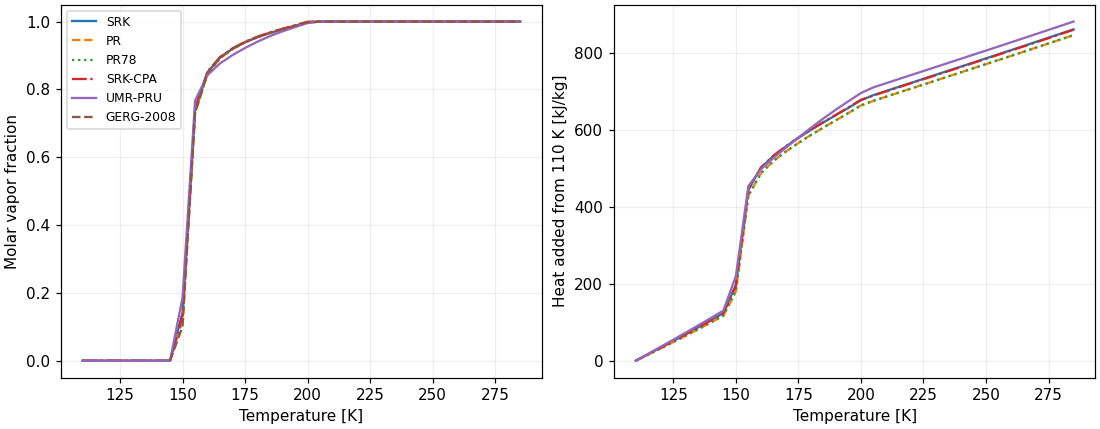

In [4]:
feed = {"methane": 0.92, "ethane": 0.05, "propane": 0.02, "nitrogen": 0.01}
pressure = 10.0
temperatures = np.linspace(110, 285, 36)
path_rows = []
largest_balance_error = 0.0
largest_fugacity_error = 0.0

for model in mixture_models:
    for temperature in temperatures:
        try:
            fluid = tp_flash(model, feed, temperature, pressure)
        except jpype.JClass("java.lang.IllegalStateException") as exc:
            if model != "GERG-2008" or "GERG fugacity calculation" not in str(exc):
                raise
            print(f"{model}, {temperature:.0f} K: {exc.getMessage()}")
            path_rows.append([model, temperature, np.nan, np.nan])
            continue
        phases = active_phases(fluid)
        beta = np.array([phase.getBeta() for phase in phases])
        assert np.all(beta >= 0) and np.isclose(beta.sum(), 1, atol=1e-12)
        for index, fraction in enumerate(feed.values()):
            components = [phase.getComponent(index) for phase in phases]
            compositions = np.array([component.getx() for component in components])
            balance_error = abs(beta @ compositions - fraction)
            largest_balance_error = max(largest_balance_error, balance_error)
            if len(phases) == 2 and min(beta) > 1e-8:
                fugacities = [
                    component.getx() * component.getFugacityCoefficient()
                    for component in components
                ]
                fugacity_error = abs(np.log(fugacities[0] / fugacities[1]))
                largest_fugacity_error = max(largest_fugacity_error, fugacity_error)
        vapor_fraction = sum(p.getBeta() for p in phases if str(p.getType()) == "GAS")
        if model == "GERG-2008" and len(phases) == 1 and vapor_fraction > 0.99:
            density = phases[0].getDensity("kg/m3")
            if density > 300:
                # Flag a dense phase with a GAS label in this particular LNG example.
                print(f"{model}, {temperature:.0f} K: GAS label at {density:.1f} kg/m³")
                vapor_fraction = np.nan
        path_rows.append([model, temperature, vapor_fraction, fluid.getEnthalpy("kJ/kg")])

assert largest_balance_error < 1e-8, largest_balance_error
assert largest_fugacity_error < 1e-5, largest_fugacity_error
print(f"Max component balance residual: {largest_balance_error:.2e} mole fraction")
print(f"Max two-phase log fugacity residual: {largest_fugacity_error:.2e}")

path = pd.DataFrame(path_rows, columns=["EOS", "T", "Vapor fraction", "h"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), layout="constrained")
duties = []
for model_index, (model, results) in enumerate(path.groupby("EOS", sort=False)):
    delta_h = results.h - results.h.iloc[0]
    style = ("-", "--", ":", "-.")[model_index % 4]
    axes[0].plot(results["T"], results["Vapor fraction"], style, label=model)
    axes[1].plot(results["T"], delta_h, style)
    if pd.notna(delta_h.iloc[-1]):
        assert results["Vapor fraction"].iloc[0] < 1e-8
        assert results["Vapor fraction"].iloc[-1] > 1 - 1e-8
        assert delta_h.iloc[-1] > 0
    duties.append([model, delta_h.iloc[-1]])
axes[0].set(ylabel="Molar vapor fraction", xlabel="Temperature [K]")
axes[1].set(ylabel="Heat added from 110 K [kJ/kg]", xlabel="Temperature [K]")
axes[0].legend(fontsize=8)
for axis in axes:
    axis.grid(alpha=0.2)
figure_png = BytesIO()
fig.savefig(figure_png, format="png", dpi=110)
plt.close(fig)
display({"image/png": b64encode(figure_png.getvalue()).decode("ascii")}, raw=True)
print(pd.DataFrame(duties, columns=["EOS", "110 to 285 K [kJ/kg]"])
      .round(2).to_string(index=False, na_rep="—"))

## 3. Inspect phase properties at 170 K

Read properties from each active phase after the flash. $Z$ is the compressibility factor, $\phi_{\mathrm{CH_4}}$ is methane's fugacity coefficient, $C_p$ and $C_v$ are molar heat capacities, and $a$ is the phase sound speed. Convert phase sound speed to the adiabatic bulk modulus with density $\rho$.

$$K_s=\rho a^2$$

A two-phase pipe model needs its own acoustic closure. Phase sound speeds alone cannot predict the propagation speed of an equilibrium or frozen two-phase mixture.

In [5]:
phase_rows = []
for model in mixture_models:
    fluid = tp_flash(model, feed, 170.0, pressure)
    for phase in active_phases(fluid):
        density = phase.getDensity("kg/m3")
        sound_speed = phase.getSoundSpeed()
        assert density > 0 and sound_speed > 0
        phase_rows.append([
            model, str(phase.getType()), phase.getBeta(), phase.getZ(),
            phase.getComponent(0).getFugacityCoefficient(), density,
            phase.getCp("J/molK"), phase.getCv("J/molK"), sound_speed,
            density * sound_speed**2 / 1e6,
            phase.getJouleThomsonCoefficient("K/bar"),
        ])
properties = pd.DataFrame(phase_rows, columns=[
    "EOS", "Phase", "β", "Z", "φ CH₄", "ρ [kg/m³]", "Cp [J/mol/K]", "Cv [J/mol/K]",
    "a [m/s]", "Ks [MPa]", "JT [K/bar]",
])
print(properties.round(4).to_string(index=False))

      EOS  Phase      β      Z  φ CH₄  ρ [kg/m³]  Cp [J/mol/K]  Cv [J/mol/K]   a [m/s]  Ks [MPa]  JT [K/bar]
      SRK    GAS 0.9196 0.8847 0.8991    13.2085       37.6545       24.9090  316.3814    1.3221      1.3547
      SRK    OIL 0.0804 0.0390 2.2234   529.9300       70.8796       46.0882 1064.0343  599.9703     -0.0426
       PR    GAS 0.9189 0.8756 0.8909    13.2916       37.5301       24.8304  313.0387    1.3025      1.3845
       PR    OIL 0.0811 0.0345 2.1339   509.5137       67.2752       43.1697 1083.3984  598.0427     -0.0403
     PR78    GAS 0.9189 0.8756 0.8909    13.2916       37.5301       24.8304  313.0387    1.3025      1.3845
     PR78    OIL 0.0811 0.0345 2.1339   509.5137       67.2752       43.1697 1083.3984  598.0427     -0.0403
  SRK-CPA    GAS 0.9212 0.8846 0.8991    13.2075       37.6628       24.9132  316.2871    1.3212      1.3556
  SRK-CPA    OIL 0.0788 0.0381 2.2696   521.4030       69.8871       45.5914 1062.7518  588.8941     -0.0426
  UMR-PRU    GAS 0.

## 4. Check the hydrogen Joule–Thomson coefficient

For a single phase, compare the native getter with a centered derivative of molar enthalpy $h$ and the independent HEOS getter. Temperature is in kelvin and pressure is in bar, so the ratio is in K/bar. Positive values imply cooling on an infinitesimal isenthalpic pressure drop.

$$\mu_{JT}=-\frac{(\partial h/\partial P)_T}{(\partial h/\partial T)_P}$$

In [6]:
def hydrogen_enthalpy(temperature, pressure):
    fluid = tp_flash("Leachman", {"hydrogen": 1.0}, temperature, pressure)
    assert fluid.getNumberOfPhases() == 1
    return fluid.getPhase(0).getEnthalpy("J/mol")

def hydrogen_jt_difference(temperature, pressure, step_t, step_p):
    dh_dp = (hydrogen_enthalpy(temperature, pressure + step_p)
             - hydrogen_enthalpy(temperature, pressure - step_p)) / (2 * step_p)
    dh_dt = (hydrogen_enthalpy(temperature + step_t, pressure)
             - hydrogen_enthalpy(temperature - step_t, pressure)) / (2 * step_t)
    return -dh_dp / dh_dt

jt_rows = []
for temperature, pressure_bara in [(25., 5.), (100., 10.), (250., 35.)]:
    fluid = tp_flash("Leachman", {"hydrogen": 1.0}, temperature, pressure_bara)
    native = fluid.getPhase(0).getJouleThomsonCoefficient("K/bar")
    difference = hydrogen_jt_difference(temperature, pressure_bara, 0.001, 0.001)
    refined = hydrogen_jt_difference(temperature, pressure_bara, 0.0005, 0.0005)
    reference = PropsSI(
        "d(T)/d(P)|Hmass", "T", temperature, "P", pressure_bara * 1e5, "Hydrogen",
    ) * 1e5
    assert np.isclose(refined, difference, rtol=1e-4)
    assert np.isclose(difference, reference, rtol=1e-3)
    jt_rows.append([temperature, pressure_bara, native, difference, reference, native / reference])

print(pd.DataFrame(jt_rows, columns=[
    "T [K]", "P [bara]", "Native [K/bar]", "Finite diff. [K/bar]", "HEOS [K/bar]", "Native/HEOS",
]).round(6).to_string(index=False))

 T [K]  P [bara]  Native [K/bar]  Finite diff. [K/bar]  HEOS [K/bar]  Native/HEOS
  25.0       5.0       -0.433184             -0.043318     -0.043319     9.999942
 100.0      10.0        1.251567              0.125157      0.125157     9.999957
 250.0      35.0       -0.216516             -0.021652     -0.021652     9.999947


## Interpretation and follow-up

- At normal pressure, GERG-2008 methane and HEOS normal hydrogen give saturated-liquid densities close to the published Table 1 values. The Leachman bubble-point call in the pinned release fails the equilibrium check and is excluded from the saturation table. [NeqSim #5286](https://github.com/equinor/neqsim/issues/5286) The table also shows how model choice affects latent heat and liquid density even when boiling temperature agrees.
- Failed GERG-2008 states and dense single phases labelled GAS are logged and leave gaps in the vapor-fraction path. The 300 kg/m³ flag is a case-specific plotting screen. Full-range heating duty requires a valid 110 K inlet. The 170 K GERG-2008 flash is shown separately. [NeqSim #5285](https://github.com/equinor/neqsim/issues/5285)
- For the synthetic LNG case, the model spread measures sensitivity to the EOS and mixing rule. Fugacity and mass-balance closure test the computation. Experimental mixture VLE, density and caloric data would be needed to rank predictive accuracy. The UMR-PRU heat capacity at 170 K is particularly sensitive to model choice.
- The Leachman Joule–Thomson getter in the tested release gives a value ten times the enthalpy derivative and HEOS comparison. The independent derivative reproduces the magnitude and sign across both step sizes. [NeqSim #5283](https://github.com/equinor/neqsim/issues/5283)
- A traceable regression fixture should retain pressure, units, phase and hydrogen spin isomer, then add measured mixture states and model-specific tolerances. [NeqSim #5284](https://github.com/equinor/neqsim/issues/5284)

Try repeating the LNG path at another pressure or increasing nitrogen by 1 mol% while taking the same amount from methane. Compare the condensation range and heating requirement. These cases describe dry fluid-phase behavior, with solids and water outside the scope.

**Sources** · [Nwosi (2025), Tables 1–2](https://doi.org/10.53022/oarjet.2025.8.2.0038) · [Leachman et al. (2009), hydrogen spin-isomer equations](https://doi.org/10.1063/1.3160306) · [CoolProp fluid models](https://coolprop.org/fluid_properties/PurePseudoPure.html) · [NeqSim](https://github.com/equinor/neqsim)